In [1]:
import numpy as np
import scipy.interpolate as si
import matplotlib.pyplot as plt

In [5]:
def sinxy(x,y):
    return np.sin(x)*np.sin(y)


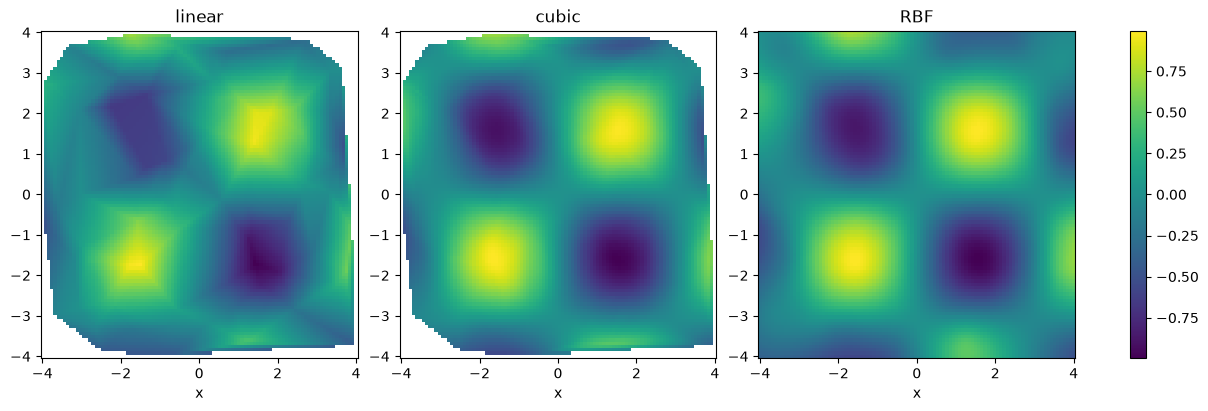

In [ ]:
rgn = np.random.default_rng(seed = 43)
pts = rgn.uniform(-4,4,size=(100,2))
z = sinxy(pts[:,0], pts[:,1])

xnew = np.linspace(-4,4,100)
Xnew, Ynew = np.meshgrid(xnew, xnew, indexing="ij")

plin = si.griddata(pts, z, (Xnew, Ynew), method = "linear")
pcub = si.griddata(pts, z, (Xnew, Ynew), method = "cubic")

rbf = si.RBFInterpolator(pts, z)
prbf = rbf(np.column_stack( [Xnew.ravel(), Ynew.ravel()])).reshape(Xnew.shape)

fig, axs = plt.subplots(1,3, figsize = (12,4), layout = "constrained")

methods = [ ("linear", plin), ("cubic", pcub), ("RBF", prbf)]

for ax, (m, p) in zip(axs, methods):
    im = ax.pcolormesh(Xnew, Ynew, p)
    
    ax.set_title(m)
    ax.set_xlabel("x")
    
fig.colorbar(im, ax=axs)
plt.show()


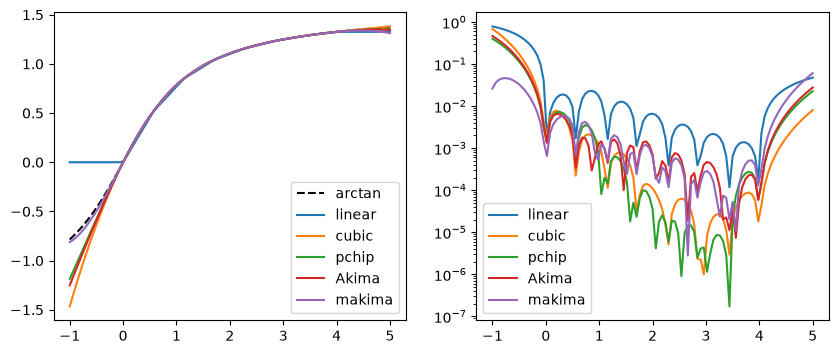

In [13]:
x = np.linspace(0,4,8)
y = np.arctan(x)

names = ["linear", "cubic", "pchip", "Akima", "makima"]

methods = [
    lambda z: np.interp(z,x,y),
    si.CubicSpline(x,y),
    si.PchipInterpolator(x,y),
    si.Akima1DInterpolator(x,y,method="akima", extrapolate = True),
    si.Akima1DInterpolator(x,y,method="makima", extrapolate = True)
    ]
xnew = np.linspace(-1,5,101)
fig,ax = plt.subplots(1,2,figsize=(10,4))

ax[0].plot(xnew, np.arctan(xnew), 'k--', label = "arctan")
for n,m in zip(names, methods):
    ax[0].plot(xnew, m(xnew), label = n)
    ax[1].semilogy(xnew, np.abs(np.arctan(xnew)-m(xnew))+ 1e-16, label = n)

ax[0].legend()
ax[1].legend()
plt.show()

secret number is 651